# Options Trading Masterclass
### Pricing theory, the Greeks, and volatility modelling — from Black-Scholes to Heston, SABR and jump-diffusion

This notebook is a self-contained, research-grounded tour of options pricing. Every model
implemented here traces back to a specific paper, and every closed-form formula is checked
numerically (against finite differences, Monte Carlo, or a second independent model) before
it is used. The goal is not just "here is the formula" but *why the formula is what it is*,
*what it assumes*, and *where it breaks*.

**Structure**

1. Option fundamentals — payoffs, moneyness, put-call parity
2. The Black-Scholes-Merton model
3. The Greeks — first order and higher order (Vanna, Volga, Charm, Speed, Color, Zomma)
4. Implied volatility and the volatility smile
5. Binomial and trinomial trees
6. Monte Carlo methods (variance reduction, Longstaff-Schwartz for American options)
7. Finite-difference PDE methods (Crank-Nicolson, Brennan-Schwartz for early exercise)
8. Stochastic volatility — the Heston model
9. Local volatility — Dupire's formula
10. The SABR model
11. Jump-diffusion — Merton (1976)
12. Building and checking a volatility surface
13. Trading structures and portfolio Greeks
14. Delta-hedging simulation: theta vs. gamma P&L
15. Model comparison — what to use when
16. References

**Disclaimer.** This notebook is educational material on derivatives pricing theory. Nothing
here is investment advice, and none of the code is production risk infrastructure — real
trading systems need far more care around calibration stability, data quality, and market
microstructure than a teaching notebook can show.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq, least_squares
from scipy.integrate import quad
from dataclasses import dataclass

np.random.seed(7)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["font.size"] = 11

# Reference market: a single underlying used consistently across every section
S0    = 100.0   # spot
K0    = 100.0   # a representative at-the-money strike
r     = 0.03    # risk-free rate (continuously compounded)
q     = 0.01    # continuous dividend yield
T0    = 1.0     # 1 year to expiry
sigma0 = 0.20   # flat Black-Scholes volatility for comparison purposes

print(f"S0={S0}, K0={K0}, r={r}, q={q}, T0={T0}, sigma0={sigma0}")

S0=100.0, K0=100.0, r=0.03, q=0.01, T0=1.0, sigma0=0.2


## 1. Option fundamentals

A **European call** gives the right (not obligation) to buy the underlying at strike $K$ at
expiry $T$; a **European put** the right to sell. Payoffs at expiry:

$$
\text{Call}_T = \max(S_T - K, 0), \qquad \text{Put}_T = \max(K - S_T, 0)
$$

**Put-call parity** is a *model-free* no-arbitrage identity — it holds regardless of what
process $S_t$ follows, as long as there is no early exercise and the underlying pays a
continuous yield $q$:

$$
C - P = S_0 e^{-qT} - K e^{-rT}
$$

It comes from comparing two portfolios with identical payoffs at $T$: (long call + short put)
replicates a forward contract. If parity is violated, a static long/short in both options and
the forward is a riskless arbitrage. We'll use parity throughout as a sanity check on every
pricing model we build — if a model's call and put prices don't satisfy parity to numerical
precision, something in the implementation is wrong.

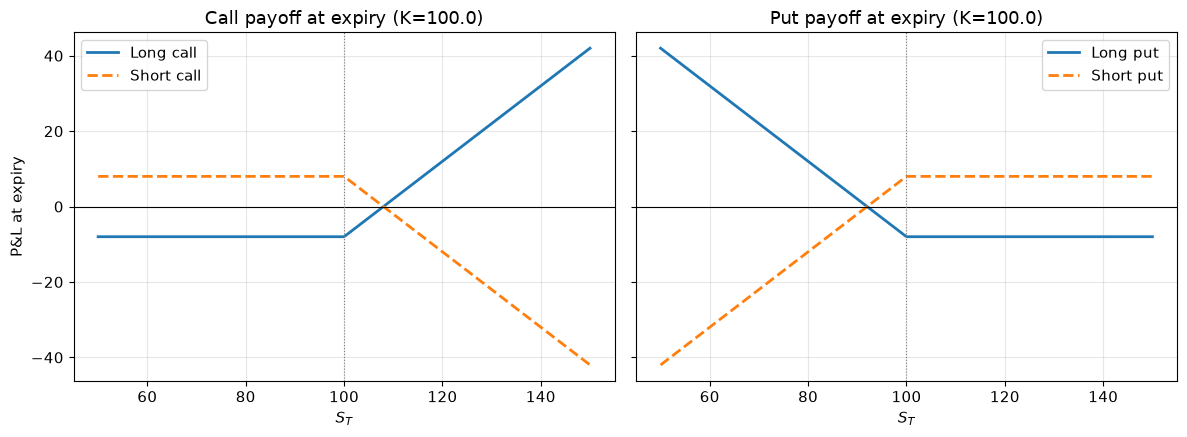

In [2]:
def payoff(S_T, K, kind):
    if kind == "call":
        return np.maximum(S_T - K, 0.0)
    elif kind == "put":
        return np.maximum(K - S_T, 0.0)
    raise ValueError(kind)

S_T_grid = np.linspace(50, 150, 400)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, kind in zip(axes, ["call", "put"]):
    long_pnl = payoff(S_T_grid, K0, kind) - 8.0   # premium paid, illustrative
    short_pnl = -payoff(S_T_grid, K0, kind) + 8.0
    ax.plot(S_T_grid, long_pnl, label=f"Long {kind}", lw=2)
    ax.plot(S_T_grid, short_pnl, label=f"Short {kind}", lw=2, ls="--")
    ax.axhline(0, color="k", lw=0.8)
    ax.axvline(K0, color="gray", lw=0.8, ls=":")
    ax.set_title(f"{kind.capitalize()} payoff at expiry (K={K0})")
    ax.set_xlabel("$S_T$")
    ax.legend()
axes[0].set_ylabel("P&L at expiry")
plt.tight_layout()
plt.show()

## 2. The Black-Scholes-Merton model

**Source:** Black & Scholes (1973), *The Pricing of Options and Corporate Liabilities*, JPE;
Merton (1973), *Theory of Rational Option Pricing*, Bell J. Econ. — Merton's paper is what
adds the continuous dividend yield $q$ and formalises the no-arbitrage replication argument.

**Assumptions:** $S_t$ follows geometric Brownian motion, $dS_t = \mu S_t\,dt + \sigma S_t\,dW_t$,
with constant $\sigma$, constant $r$, continuous trading, no transaction costs, and the
underlying can be shorted freely.

**The argument.** Build a portfolio long one option and short $\Delta = \partial V/\partial S$
shares. Itô's lemma gives the option's dynamics; choosing $\Delta$ eliminates the $dW_t$ term,
leaving a *locally riskless* portfolio, which by no-arbitrage must earn the risk-free rate.
This produces the **Black-Scholes PDE**:

$$
\frac{\partial V}{\partial t} + (r-q) S \frac{\partial V}{\partial S} + \frac12 \sigma^2 S^2 \frac{\partial^2 V}{\partial S^2} - rV = 0
$$

Solving this PDE with the terminal condition $V(S,T)=\max(S-K,0)$ (equivalently, taking the
discounted risk-neutral expectation $C = e^{-rT}\mathbb{E}^{\mathbb{Q}}[\max(S_T-K,0)]$ under
$dS_t = (r-q)S_t\,dt + \sigma S_t\,dW_t^{\mathbb{Q}}$) gives the closed-form price:

$$
d_1 = \frac{\ln(S/K) + (r - q + \tfrac12\sigma^2)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}
$$
$$
C = S e^{-qT} N(d_1) - K e^{-rT} N(d_2), \qquad P = K e^{-rT} N(-d_2) - S e^{-qT} N(-d_1)
$$

$N(\cdot)$ is the standard normal CDF. $N(d_2)$ is the risk-neutral probability the option
expires in the money; $S e^{-qT}N(d_1)$ is the present value of the asset delivered if exercised.

In [3]:
def bs_d1_d2(S, K, T, r, q, sigma):
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return d1, d2

def bs_price(S, K, T, r, q, sigma, kind="call"):
    d1, d2 = bs_d1_d2(S, K, T, r, q, sigma)
    if kind == "call":
        return S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    elif kind == "put":
        return K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(-d1)
    raise ValueError(kind)

c = bs_price(S0, K0, T0, r, q, sigma0, "call")
p = bs_price(S0, K0, T0, r, q, sigma0, "put")
parity_lhs, parity_rhs = c - p, S0 * np.exp(-q * T0) - K0 * np.exp(-r * T0)
print(f"Call = {c:.4f}   Put = {p:.4f}")
print(f"Put-call parity check: C - P = {parity_lhs:.6f}  vs  S e^-qT - K e^-rT = {parity_rhs:.6f}"
      f"  (diff={abs(parity_lhs-parity_rhs):.2e})")

Call = 8.8273   Put = 6.8669
Put-call parity check: C - P = 1.960430  vs  S e^-qT - K e^-rT = 1.960430  (diff=0.00e+00)


### Sanity check against brute-force risk-neutral simulation

Before trusting the closed form for anything downstream, we check it against the *definition*
of the price: simulate $S_T$ under the risk-neutral GBM directly and average the discounted
payoff. This is slow and noisy compared to the closed form, but it makes no use of the formula
itself, so agreement is a genuine independent check.

In [4]:
rng = np.random.default_rng(1)
n_paths = 2_000_000
Z = rng.standard_normal(n_paths)
S_T = S0 * np.exp((r - q - 0.5 * sigma0**2) * T0 + sigma0 * np.sqrt(T0) * Z)
mc_call = np.exp(-r * T0) * np.mean(np.maximum(S_T - K0, 0.0))
mc_se = np.exp(-r * T0) * np.std(np.maximum(S_T - K0, 0.0)) / np.sqrt(n_paths)
print(f"Closed-form call: {c:.4f}")
print(f"Brute-force MC:   {mc_call:.4f}  +/- {1.96*mc_se:.4f}  (95% CI)")
assert abs(mc_call - c) < 5 * mc_se, "closed form outside MC confidence interval"

Closed-form call: 8.8273
Brute-force MC:   8.8225  +/- 0.0189  (95% CI)


## 3. The Greeks

The Greeks are partial derivatives of the option price with respect to its inputs. They are
what a trading desk actually risk-manages against — nobody hedges "the option," they hedge its
sensitivities.

**First order:**

$$
\Delta = \frac{\partial V}{\partial S} = e^{-qT}N(d_1) \ \ (\text{call}), \quad e^{-qT}(N(d_1)-1)\ \ (\text{put})
$$
$$
\Gamma = \frac{\partial^2 V}{\partial S^2} = \frac{e^{-qT}\phi(d_1)}{S\sigma\sqrt{T}} \quad \text{(same for call and put)}
$$
$$
\mathcal{V} \ (\text{vega}) = \frac{\partial V}{\partial \sigma} = S e^{-qT}\phi(d_1)\sqrt{T} \quad \text{(same for call and put)}
$$
$$
\Theta = \frac{\partial V}{\partial t} = -\frac{S e^{-qT}\phi(d_1)\sigma}{2\sqrt{T}} - rKe^{-rT}N(\pm d_2) + qSe^{-qT}N(\pm d_1)
$$
$$
\rho = \frac{\partial V}{\partial r} = \pm KTe^{-rT}N(\pm d_2)
$$

where $\phi$ is the standard normal PDF and the $\pm$ signs are $+$ for calls, $-$ for puts
(with $N(-d_2), N(-d_1)$ for puts). $\Gamma$ and vega are always positive for long options —
they measure convexity, which is what you're paying for.

In [5]:
def bs_greeks(S, K, T, r, q, sigma, kind="call"):
    d1, d2 = bs_d1_d2(S, K, T, r, q, sigma)
    pdf_d1 = norm.pdf(d1)
    disc_q, disc_r = np.exp(-q * T), np.exp(-r * T)

    gamma = disc_q * pdf_d1 / (S * sigma * np.sqrt(T))
    vega = S * disc_q * pdf_d1 * np.sqrt(T)   # per 1.00 (100 vol points) change in sigma

    if kind == "call":
        delta = disc_q * norm.cdf(d1)
        theta = (-S * disc_q * pdf_d1 * sigma / (2 * np.sqrt(T))
                 - r * K * disc_r * norm.cdf(d2) + q * S * disc_q * norm.cdf(d1))
        rho = K * T * disc_r * norm.cdf(d2)
    elif kind == "put":
        delta = disc_q * (norm.cdf(d1) - 1)
        theta = (-S * disc_q * pdf_d1 * sigma / (2 * np.sqrt(T))
                 + r * K * disc_r * norm.cdf(-d2) - q * S * disc_q * norm.cdf(-d1))
        rho = -K * T * disc_r * norm.cdf(-d2)
    else:
        raise ValueError(kind)

    return {"delta": delta, "gamma": gamma, "vega": vega, "theta": theta, "rho": rho}

g = bs_greeks(S0, K0, T0, r, q, sigma0, "call")
print("ATM call Greeks:", {k: round(v, 5) for k, v in g.items()})

ATM call Greeks: {'delta': np.float64(0.5735), 'gamma': np.float64(0.01936), 'vega': np.float64(38.71518), 'theta': np.float64(-4.75369), 'rho': np.float64(48.52228)}


### Numerical check: closed-form Greeks vs. central finite differences

In [6]:
def fd_greeks(S, K, T, r, q, sigma, kind="call", h=1e-4):
    price = lambda S_, T_, sigma_, r_: bs_price(S_, K, T_, r_, q, sigma_, kind)
    delta = (price(S + h, T, sigma, r) - price(S - h, T, sigma, r)) / (2 * h)
    gamma = (price(S + h, T, sigma, r) - 2 * price(S, T, sigma, r) + price(S - h, T, sigma, r)) / h**2
    vega  = (price(S, T, sigma + h, r) - price(S, T, sigma - h, r)) / (2 * h)
    theta = -(price(S, T + h, sigma, r) - price(S, T - h, sigma, r)) / (2 * h)   # d/dt = -d/dT
    rho   = (price(S, T, sigma, r + h) - price(S, T, sigma, r - h)) / (2 * h)
    return {"delta": delta, "gamma": gamma, "vega": vega, "theta": theta, "rho": rho}

fd = fd_greeks(S0, K0, T0, r, q, sigma0, "call")
rows = []
for name in g:
    rows.append({"greek": name, "closed_form": g[name], "finite_diff": fd[name],
                 "abs_diff": abs(g[name] - fd[name])})
df_check = pd.DataFrame(rows).set_index("greek")
print(df_check.to_string(float_format=lambda x: f"{x:.6f}"))
assert (df_check["abs_diff"] < 1e-3).all()

       closed_form  finite_diff  abs_diff
greek                                    
delta     0.573496     0.573496  0.000000
gamma     0.019358     0.019356  0.000002
vega     38.715175    38.715175  0.000000
theta    -4.753690    -4.753690  0.000000
rho      48.522277    48.522276  0.000001


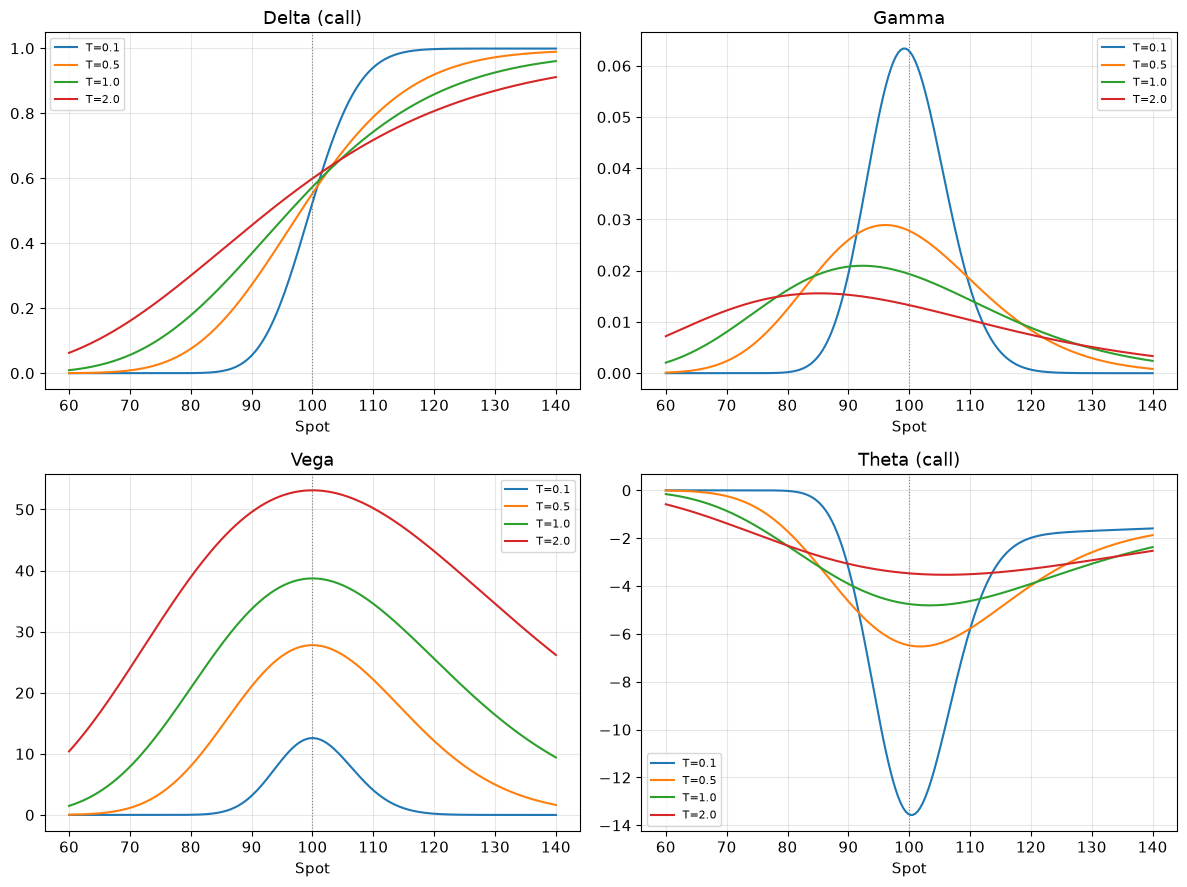

In [7]:
S_grid = np.linspace(60, 140, 200)
maturities = [0.1, 0.5, 1.0, 2.0]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for T_ in maturities:
    d = bs_greeks(S_grid, K0, T_, r, q, sigma0, "call")
    axes[0, 0].plot(S_grid, d["delta"], label=f"T={T_}")
    axes[0, 1].plot(S_grid, d["gamma"], label=f"T={T_}")
    axes[1, 0].plot(S_grid, d["vega"], label=f"T={T_}")
    axes[1, 1].plot(S_grid, d["theta"], label=f"T={T_}")

for ax, title in zip(axes.flat, ["Delta (call)", "Gamma", "Vega", "Theta (call)"]):
    ax.set_title(title); ax.set_xlabel("Spot"); ax.axvline(K0, color="gray", ls=":", lw=0.8)
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Higher-order Greeks

These matter for hedging a Greek-neutral book, not just the position itself — e.g. Vanna tells
you how much your delta hedge will drift if implied vol moves, which is exactly the risk a
delta-and-vega-hedged book still carries.

$$
\text{Vanna} = \frac{\partial^2 V}{\partial S\,\partial \sigma} = \frac{\partial \Delta}{\partial \sigma} = \frac{\partial \mathcal V}{\partial S} = -e^{-qT}\phi(d_1)\frac{d_2}{\sigma}
$$
$$
\text{Volga (Vomma)} = \frac{\partial^2 V}{\partial \sigma^2} = \frac{\partial \mathcal V}{\partial \sigma} = \mathcal{V}\,\frac{d_1 d_2}{\sigma}
$$
$$
\text{Charm} = -\frac{\partial \Delta}{\partial t} = e^{-qT}\phi(d_1)\left[\frac{2(r-q)T - d_2\sigma\sqrt{T}}{2T\sigma\sqrt{T}}\right] - q e^{-qT} N(\pm d_1)\cdot(\text{sign})
$$
$$
\text{Speed} = \frac{\partial \Gamma}{\partial S} = -\frac{\Gamma}{S}\left(\frac{d_1}{\sigma\sqrt T} + 1\right), \qquad
\text{Zomma} = \frac{\partial \Gamma}{\partial \sigma} = \Gamma\,\frac{d_1 d_2 - 1}{\sigma}
$$

We implement Vanna, Volga, Speed and Zomma (clean closed forms) and check them against finite
differences of the first-order Greeks rather than re-deriving Charm's sign convention by hand.

In [8]:
def bs_higher_greeks(S, K, T, r, q, sigma, kind="call"):
    d1, d2 = bs_d1_d2(S, K, T, r, q, sigma)
    pdf_d1 = norm.pdf(d1)
    disc_q = np.exp(-q * T)
    gamma = disc_q * pdf_d1 / (S * sigma * np.sqrt(T))
    vega = S * disc_q * pdf_d1 * np.sqrt(T)

    vanna = -disc_q * pdf_d1 * d2 / sigma
    volga = vega * d1 * d2 / sigma
    speed = -gamma / S * (d1 / (sigma * np.sqrt(T)) + 1)
    zomma = gamma * (d1 * d2 - 1) / sigma
    return {"vanna": vanna, "volga": volga, "speed": speed, "zomma": zomma}

hg = bs_higher_greeks(S0, K0, T0, r, q, sigma0, "call")

# Check vanna = d(vega)/dS and volga = d(vega)/d(sigma) via finite differences
h = 1e-4
vega_up_S = bs_greeks(S0 + h, K0, T0, r, q, sigma0, "call")["vega"]
vega_dn_S = bs_greeks(S0 - h, K0, T0, r, q, sigma0, "call")["vega"]
fd_vanna = (vega_up_S - vega_dn_S) / (2 * h)

vega_up_sig = bs_greeks(S0, K0, T0, r, q, sigma0 + h, "call")["vega"]
vega_dn_sig = bs_greeks(S0, K0, T0, r, q, sigma0 - h, "call")["vega"]
fd_volga = (vega_up_sig - vega_dn_sig) / (2 * h)

print(f"Vanna: closed-form={hg['vanna']:.6f}  finite-diff={fd_vanna:.6f}")
print(f"Volga: closed-form={hg['volga']:.6f}  finite-diff={fd_volga:.6f}")
print(f"Speed: {hg['speed']:.6f}   Zomma: {hg['zomma']:.6f}")
assert abs(hg["vanna"] - fd_vanna) < 1e-3
assert abs(hg["volga"] - fd_volga) < 1e-3

Vanna: closed-form=0.000000  finite-diff=0.000000
Volga: closed-form=-0.000000  finite-diff=0.000001
Speed: -0.000387   Zomma: -0.096788


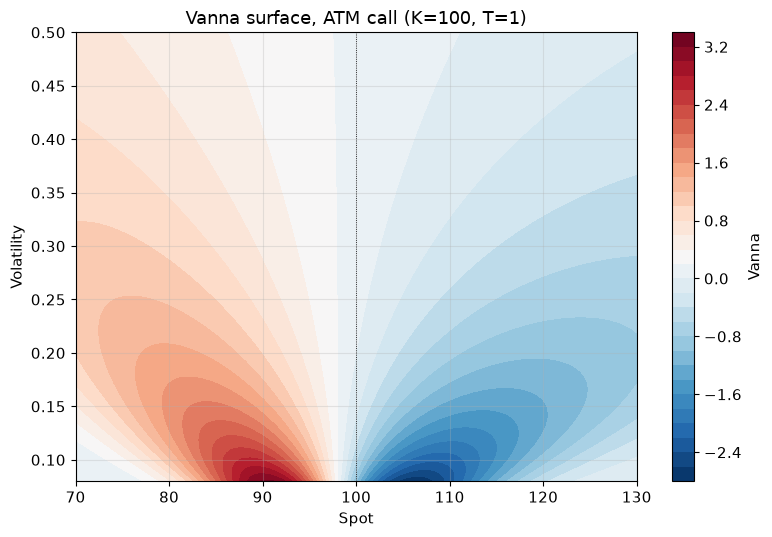

In [9]:
S_grid2 = np.linspace(70, 130, 120)
vol_grid = np.linspace(0.08, 0.5, 120)
SS, VV = np.meshgrid(S_grid2, vol_grid)
vanna_surf = bs_higher_greeks(SS, K0, T0, r, q, VV, "call")["vanna"]

fig, ax = plt.subplots(figsize=(8, 5.5))
cf = ax.contourf(SS, VV, vanna_surf, levels=30, cmap="RdBu_r")
plt.colorbar(cf, ax=ax, label="Vanna")
ax.set_xlabel("Spot"); ax.set_ylabel("Volatility"); ax.set_title("Vanna surface, ATM call (K=100, T=1)")
ax.axvline(K0, color="k", lw=0.6, ls=":")
plt.tight_layout(); plt.show()

## 4. Implied volatility and the smile

Implied volatility $\sigma_{\text{imp}}$ is the value of $\sigma$ that makes the Black-Scholes
formula match an observed market price. Because $\partial C/\partial \sigma = \text{vega} > 0$,
the map $\sigma \mapsto C(\sigma)$ is strictly increasing, so the inversion has a unique
solution. Two standard root-finders:

- **Newton-Raphson** using vega as the analytic derivative — fast (quadratic convergence) but
  can misbehave for deep OTM options where vega is tiny.
- **Brent's method** — bracketed, derivative-free, guaranteed to converge given a sign change;
  the robust fallback.

If Black-Scholes were literally true, implied vol would be flat across strike and maturity for
a given underlying. It never is: equity index options show a **skew** (OTM puts trade at
higher implied vol than OTM calls — crash risk is priced in), and many other markets show a
**smile** (both wings elevated relative to ATM). Later sections build models — jump-diffusion,
stochastic volatility, local volatility — whose entire point is to *generate* this shape
endogenously rather than treat it as an unexplained market fact.

In [10]:
def implied_vol_newton(price, S, K, T, r, q, kind="call", sigma0_guess=0.3, tol=1e-8, max_iter=100):
    sigma = sigma0_guess
    for _ in range(max_iter):
        model_price = bs_price(S, K, T, r, q, sigma, kind)
        vega = bs_greeks(S, K, T, r, q, sigma, kind)["vega"]
        diff = model_price - price
        if abs(diff) < tol:
            return sigma
        if vega < 1e-10:
            break
        sigma -= diff / vega
        sigma = max(sigma, 1e-6)
    return implied_vol_brent(price, S, K, T, r, q, kind)   # fallback

def implied_vol_brent(price, S, K, T, r, q, kind="call", lo=1e-6, hi=5.0):
    f = lambda sig: bs_price(S, K, T, r, q, sig, kind) - price
    return brentq(f, lo, hi, xtol=1e-10)

# Round-trip check: price at true vol, recover it
true_vol = 0.27
test_price = bs_price(S0, 95, T0, r, q, true_vol, "put")
recovered_newton = implied_vol_newton(test_price, S0, 95, T0, r, q, "put")
recovered_brent = implied_vol_brent(test_price, S0, 95, T0, r, q, "put")
print(f"True vol: {true_vol}   Newton recovered: {recovered_newton:.8f}   Brent recovered: {recovered_brent:.8f}")

True vol: 0.27   Newton recovered: 0.27000000   Brent recovered: 0.27000000


## 5. Binomial trees

**Source:** Cox, Ross & Rubinstein (1979), *Option Pricing: A Simplified Approach*, J. Fin.
Econ. The CRR tree discretises GBM into $N$ steps of length $\Delta t = T/N$, with up/down
factors and risk-neutral probability chosen to match the first two moments of the continuous
process:

$$
u = e^{\sigma\sqrt{\Delta t}}, \qquad d = 1/u, \qquad p = \frac{e^{(r-q)\Delta t} - d}{u - d}
$$

Price by backward induction from the terminal payoffs; at each node the value is the
discounted expectation under $p$, and for American options we additionally take the max with
the immediate-exercise value. As $N \to \infty$ the tree price converges to Black-Scholes for
European options — this is a second independent numerical method to check the closed form
against, and the only method so far that naturally handles **early exercise**.

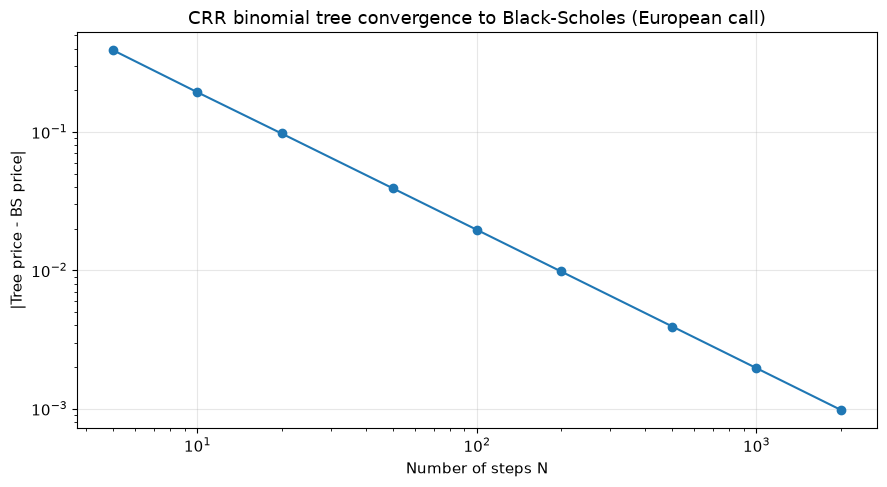

N=2000 tree price: 8.82634  vs BS: 8.82732


In [11]:
def binomial_tree_price(S, K, T, r, q, sigma, N, kind="call", american=False):
    dt = T / N
    u = np.exp(sigma * np.sqrt(dt))
    d = 1 / u
    p = (np.exp((r - q) * dt) - d) / (u - d)
    disc = np.exp(-r * dt)

    j = np.arange(N + 1)
    S_T = S * u**(N - j) * d**j
    V = payoff(S_T, K, kind)

    for step in range(N - 1, -1, -1):
        V = disc * (p * V[:-1] + (1 - p) * V[1:])
        if american:
            j = np.arange(step + 1)
            S_step = S * u**(step - j) * d**j
            V = np.maximum(V, payoff(S_step, K, kind))
    return V[0]

# Convergence to Black-Scholes as N grows
Ns = np.array([5, 10, 20, 50, 100, 200, 500, 1000, 2000])
bs_ref = bs_price(S0, K0, T0, r, q, sigma0, "call")
errors = [abs(binomial_tree_price(S0, K0, T0, r, q, sigma0, N, "call", american=False) - bs_ref) for N in Ns]

fig, ax = plt.subplots()
ax.loglog(Ns, errors, "o-")
ax.set_xlabel("Number of steps N"); ax.set_ylabel("|Tree price - BS price|")
ax.set_title("CRR binomial tree convergence to Black-Scholes (European call)")
plt.tight_layout(); plt.show()
print(f"N=2000 tree price: {binomial_tree_price(S0, K0, T0, r, q, sigma0, 2000, 'call'):.5f}  vs BS: {bs_ref:.5f}")

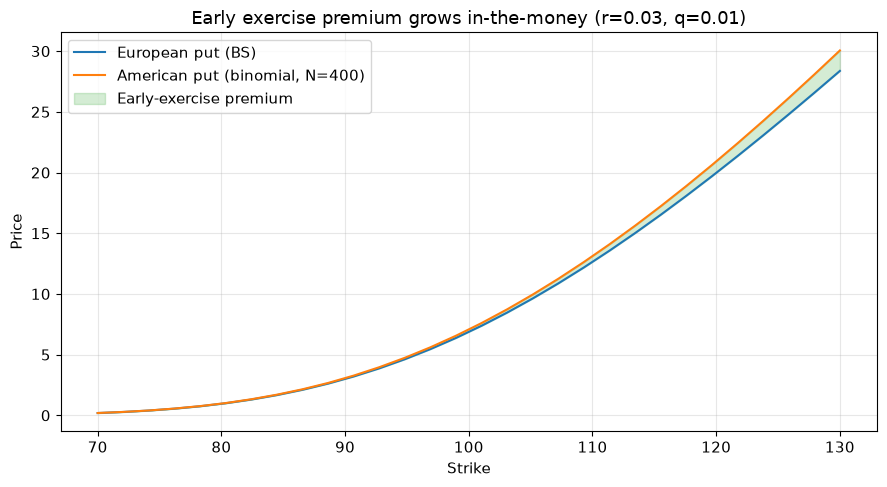

In [12]:
# Early exercise premium: American vs European put, and its dependence on dividend yield
Ks = np.linspace(70, 130, 30)
euro_puts = [bs_price(S0, K, T0, r, q, sigma0, "put") for K in Ks]
amer_puts = [binomial_tree_price(S0, K, T0, r, q, sigma0, 400, "put", american=True) for K in Ks]

fig, ax = plt.subplots()
ax.plot(Ks, euro_puts, label="European put (BS)")
ax.plot(Ks, amer_puts, label="American put (binomial, N=400)")
ax.fill_between(Ks, euro_puts, amer_puts, alpha=0.2, color="C2", label="Early-exercise premium")
ax.set_xlabel("Strike"); ax.set_ylabel("Price"); ax.legend()
ax.set_title(f"Early exercise premium grows in-the-money (r={r}, q={q})")
plt.tight_layout(); plt.show()

## 6. Monte Carlo methods

### Variance reduction

Plain Monte Carlo error scales as $O(1/\sqrt{n})$ regardless of dimension, which is exactly
why it's used for path-dependent and high-dimensional payoffs where trees and PDE grids become
impractical. Two standard variance-reduction techniques:

- **Antithetic variates.** For every draw $Z$, also use $-Z$. Since the GBM terminal value is
  a monotonic function of $Z$, the payoffs from $Z$ and $-Z$ are negatively correlated,
  reducing the variance of the paired average at no extra simulation cost per pair.
- **Control variates.** The terminal asset price $S_T$ itself has a known analytic expectation
  $\mathbb{E}[S_T] = S_0 e^{(r-q)T}$ under the risk-neutral measure. Using $S_T$ as a control
  variate for the option payoff (which is correlated with $S_T$, especially deep ITM) removes
  a chunk of variance.

### Longstaff-Schwartz for American options

**Source:** Longstaff & Schwartz (2001), *Valuing American Options by Simulation: A Simple
Least-Squares Approach*, Rev. Fin. Studies. Monte Carlo naturally prices European payoffs by
simulating forward, but American exercise requires knowing the *continuation value* at each
node, which needs backward induction — seemingly incompatible with forward simulation. LSM
resolves this: simulate all paths forward, then work backward in time, and at each exercise
date **regress the realised discounted continuation payoff onto a polynomial basis of the
current spot**, using only the in-the-money paths. The fitted regression estimates the
continuation value; compare to immediate exercise value to decide the (approximate) optimal
exercise policy, then evaluate the resulting cashflows.

In [13]:
def mc_european_call(S, K, T, r, q, sigma, n_paths, antithetic=True, control_variate=True, seed=0):
    rng = np.random.default_rng(seed)
    n_half = n_paths // 2 if antithetic else n_paths
    Z = rng.standard_normal(n_half)
    if antithetic:
        Z = np.concatenate([Z, -Z])

    S_T = S * np.exp((r - q - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    payoff_disc = np.exp(-r * T) * np.maximum(S_T - K, 0.0)

    if control_variate:
        cv = np.exp(-r * T) * S_T                       # discounted S_T, known mean
        cv_mean = S * np.exp(-q * T)                      # E[e^{-rT} S_T]
        b = np.cov(payoff_disc, cv)[0, 1] / np.var(cv)
        adjusted = payoff_disc - b * (cv - cv_mean)
        price, se = adjusted.mean(), adjusted.std(ddof=1) / np.sqrt(n_paths)
    else:
        price, se = payoff_disc.mean(), payoff_disc.std(ddof=1) / np.sqrt(n_paths)
    return price, se

n_paths = 200_000
plain_price, plain_se = mc_european_call(S0, K0, T0, r, q, sigma0, n_paths, antithetic=False, control_variate=False)
av_price, av_se = mc_european_call(S0, K0, T0, r, q, sigma0, n_paths, antithetic=True, control_variate=False)
full_price, full_se = mc_european_call(S0, K0, T0, r, q, sigma0, n_paths, antithetic=True, control_variate=True)

print(f"BS closed form:              {bs_ref:.4f}")
print(f"Plain MC:                    {plain_price:.4f}  se={plain_se:.5f}")
print(f"+ antithetic:                {av_price:.4f}  se={av_se:.5f}   (se reduction {1-av_se/plain_se:.1%})")
print(f"+ antithetic + control var.: {full_price:.4f}  se={full_se:.5f}   (se reduction {1-full_se/plain_se:.1%})")

BS closed form:              8.8273
Plain MC:                    8.8404  se=0.03057
+ antithetic:                8.8288  se=0.03057   (se reduction -0.0%)
+ antithetic + control var.: 8.8284  se=0.01301   (se reduction 57.4%)


In [14]:
def lsm_american_put(S, K, T, r, q, sigma, n_paths=20_000, n_steps=50, seed=0, degree=2):
    rng = np.random.default_rng(seed)
    dt = T / n_steps
    disc = np.exp(-r * dt)

    Z = rng.standard_normal((n_paths // 2, n_steps))
    Z = np.concatenate([Z, -Z], axis=0)                     # antithetic
    increments = (r - q - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z
    log_paths = np.log(S) + np.cumsum(increments, axis=1)
    paths = np.concatenate([np.full((log_paths.shape[0], 1), S), np.exp(log_paths)], axis=1)

    cashflow = payoff(paths[:, -1], K, "put")                # exercised at maturity if ITM
    exercise_time = np.full(paths.shape[0], n_steps)

    for t in range(n_steps - 1, 0, -1):
        S_t = paths[:, t]
        itm = S_t < K                                          # only ITM paths inform continuation
        if itm.sum() < degree + 1:
            continue
        discounted_future = cashflow[itm] * disc**(exercise_time[itm] - t)
        X = S_t[itm]
        A = np.vander(X, degree + 1)
        coefs, *_ = np.linalg.lstsq(A, discounted_future, rcond=None)
        continuation_est = A @ coefs

        immediate = K - X
        exercise_now = immediate > continuation_est
        idx = np.where(itm)[0][exercise_now]
        cashflow[idx] = immediate[exercise_now]
        exercise_time[idx] = t

    pv = cashflow * disc**exercise_time
    price = pv.mean()
    se = pv.std(ddof=1) / np.sqrt(len(pv))
    return price, se

lsm_price, lsm_se = lsm_american_put(S0, 100, T0, r, q, sigma0, n_paths=40_000, n_steps=50)
tree_amer_price = binomial_tree_price(S0, 100, T0, r, q, sigma0, 1000, "put", american=True)
euro_price = bs_price(S0, 100, T0, r, q, sigma0, "put")

print(f"European put (BS):         {euro_price:.4f}")
print(f"American put (binomial):   {tree_amer_price:.4f}")
print(f"American put (LSM):        {lsm_price:.4f}  +/- {1.96*lsm_se:.4f}")

European put (BS):         6.8669
American put (binomial):   7.0629
American put (LSM):        7.0693  +/- 0.0797


## 7. Finite-difference PDE methods

We discretise the Black-Scholes PDE directly on an $(S,t)$ grid and solve backward from
expiry using **Crank-Nicolson** — the average of explicit and implicit Euler in time, which is
unconditionally stable and second-order accurate in both $S$ and $t$. Each timestep requires
solving a tridiagonal linear system.

For American options, the **Brennan-Schwartz (1977)** algorithm (*The Valuation of American
Put Options*, J. Finance) solves this with early exercise almost for free: because the
Black-Scholes finite-difference operator has an M-matrix structure, doing the ordinary
tridiagonal (Thomas algorithm) forward elimination and then, on the *back-substitution* pass
only, projecting each value up to the intrinsic payoff, gives the correct constrained solution
$V \ge \max(K-S,0)$ without an iterative solver.

In [15]:
def crank_nicolson_american_put(S0_, K, T, r, q, sigma, M=400, N=400, S_max_mult=3):
    S_max = S_max_mult * K
    dS = S_max / M
    dt = T / N
    S_vec = np.linspace(0, S_max, M + 1)
    j = np.arange(1, M)                                   # interior nodes

    sig2 = sigma**2
    alpha = 0.25 * dt * (sig2 * j**2 - (r - q) * j)
    beta = -0.5 * dt * (sig2 * j**2 + r)
    gamma_ = 0.25 * dt * (sig2 * j**2 + (r - q) * j)

    # Crank-Nicolson: (I - 0.5 A) V^{n+1} = (I + 0.5 A) V^n  =>  build tridiagonals
    a = -alpha
    b = 1 - beta
    c = -gamma_
    a2 = alpha
    b2 = 1 + beta
    c2 = gamma_

    V = payoff(S_vec, K, "put").copy()

    for n in range(N):
        rhs = a2 * V[:-2] + b2 * V[1:-1] + c2 * V[2:]
        # boundary contributions (V=K-0=K at S=0 decays like K e^{-r tau}; ~0 at S_max for a put)
        tau = (n + 1) * dt
        V0_next = K * np.exp(-r * tau)
        rhs[0] += a[0] * V0_next
        # Thomas algorithm forward elimination
        b_ = b.copy(); rhs_ = rhs.copy()
        for i in range(1, M - 1):
            m = a[i] / b_[i - 1]
            b_[i] = b[i] - m * c[i - 1]
            rhs_[i] = rhs_[i] - m * rhs_[i - 1]
        # Brennan-Schwartz back-substitution with early-exercise projection
        V_new = np.empty(M - 1)
        payoff_int = payoff(S_vec[1:-1], K, "put")
        V_new[-1] = max(rhs_[-1] / b_[-1], payoff_int[-1])
        for i in range(M - 3, -1, -1):
            val = (rhs_[i] - c[i] * V_new[i + 1]) / b_[i]
            V_new[i] = max(val, payoff_int[i])
        V = np.concatenate([[V0_next], V_new, [0.0]])

    from scipy.interpolate import interp1d
    return float(interp1d(S_vec, V, kind="cubic")(S0_))

fd_price = crank_nicolson_american_put(S0, 100, T0, r, q, sigma0, M=400, N=400)
print(f"American put — Crank-Nicolson/Brennan-Schwartz: {fd_price:.4f}")
print(f"American put — binomial (N=1000):                {tree_amer_price:.4f}")
print(f"American put — LSM Monte Carlo:                  {lsm_price:.4f}")
print(f"European put — Black-Scholes:                     {euro_price:.4f}")

American put — Crank-Nicolson/Brennan-Schwartz: 7.0627
American put — binomial (N=1000):                7.0629
American put — LSM Monte Carlo:                  7.0693
European put — Black-Scholes:                     6.8669


## 8. Stochastic volatility — the Heston model

**Source:** Heston (1993), *A Closed-Form Solution for Options with Stochastic Volatility with
Applications to Bond and Currency Options*, Rev. Fin. Studies.

Constant $\sigma$ is the weakest Black-Scholes assumption — realised and implied vol both move
randomly and cluster. Heston models variance $v_t$ itself as a mean-reverting square-root
(CIR) process correlated with the asset:

$$
dS_t = (r-q)S_t\,dt + \sqrt{v_t}\,S_t\,dW_t^S, \qquad
dv_t = \kappa(\theta - v_t)\,dt + \xi\sqrt{v_t}\,dW_t^v, \qquad d\langle W^S, W^v\rangle_t = \rho\,dt
$$

$\kappa$ = mean-reversion speed, $\theta$ = long-run variance, $\xi$ = vol-of-vol, $\rho$ =
spot/vol correlation (typically negative for equities — the leverage effect). Despite the
extra dimension, Heston admits a **semi-analytic price** via the characteristic function of
$\ln S_T$ and Fourier inversion — we use the "Little Trap" formulation of Albrecher, Mayer,
Schoutens & Tistaert (2007) which avoids branch-cut discontinuities that plague the original
Heston (1993) formula for long maturities / high vol-of-vol.

In [16]:
def heston_char_func(u, S, T, r, q, kappa, theta, xi, rho, v0):
    x = np.log(S)
    a = kappa * theta
    b = kappa
    d = np.sqrt((rho * xi * 1j * u - b)**2 + xi**2 * (1j * u + u**2))
    g = (b - rho * xi * 1j * u - d) / (b - rho * xi * 1j * u + d)     # "little trap" g = 1/g_Heston

    C = (r - q) * 1j * u * T + (a / xi**2) * (
        (b - rho * xi * 1j * u - d) * T - 2 * np.log((1 - g * np.exp(-d * T)) / (1 - g))
    )
    D = ((b - rho * xi * 1j * u - d) / xi**2) * ((1 - np.exp(-d * T)) / (1 - g * np.exp(-d * T)))
    return np.exp(C + D * v0 + 1j * u * x)

def heston_call_price(S, K, T, r, q, kappa, theta, xi, rho, v0):
    def integrand(u, Pnum):
        if Pnum == 1:
            cf = heston_char_func(u - 1j, S, T, r, q, kappa, theta, xi, rho, v0) / heston_char_func(-1j, S, T, r, q, kappa, theta, xi, rho, v0)
        else:
            cf = heston_char_func(u, S, T, r, q, kappa, theta, xi, rho, v0)
        return np.real(np.exp(-1j * u * np.log(K)) * cf / (1j * u))

    P1 = 0.5 + (1 / np.pi) * quad(integrand, 1e-10, 200, args=(1,), limit=200)[0]
    P2 = 0.5 + (1 / np.pi) * quad(integrand, 1e-10, 200, args=(2,), limit=200)[0]
    return S * np.exp(-q * T) * P1 - K * np.exp(-r * T) * P2

# Feller condition 2*kappa*theta > xi^2 keeps variance strictly positive (Feller, 1951)
kappa_h, theta_h, xi_h, rho_h, v0_h = 2.0, 0.04, 0.35, -0.65, 0.04
feller = 2 * kappa_h * theta_h - xi_h**2
print(f"Feller condition 2*kappa*theta - xi^2 = {feller:.4f}  ({'satisfied' if feller > 0 else 'violated — variance can hit 0'})")

heston_atm = heston_call_price(S0, K0, T0, r, q, kappa_h, theta_h, xi_h, rho_h, v0_h)
bs_atm_matched_vol = bs_price(S0, K0, T0, r, q, np.sqrt(theta_h), "call")
print(f"Heston ATM call price:                 {heston_atm:.4f}")
print(f"BS call at flat vol = sqrt(theta)={np.sqrt(theta_h):.3f}:  {bs_atm_matched_vol:.4f}  (won't match exactly — vol-of-vol and skew matter)")

Feller condition 2*kappa*theta - xi^2 = 0.0375  (satisfied)
Heston ATM call price:                 8.5298
BS call at flat vol = sqrt(theta)=0.200:  8.8273  (won't match exactly — vol-of-vol and skew matter)


In [17]:
def heston_mc_price(S, K, T, r, q, kappa, theta, xi, rho, v0, n_paths=40_000, n_steps=200, seed=0, kind="call"):
    # Full-truncation Euler scheme (Lord, Koekkoek & van Dijk 2010 style) for the CIR variance.
    rng = np.random.default_rng(seed)
    dt = T / n_steps
    sqrt_dt = np.sqrt(dt)
    S_t = np.full(n_paths, S)
    v_t = np.full(n_paths, v0)
    logS = np.full(n_paths, np.log(S))

    for _ in range(n_steps):
        Z1 = rng.standard_normal(n_paths)
        Zv = rng.standard_normal(n_paths)
        Z2 = rho * Z1 + np.sqrt(1 - rho**2) * Zv
        v_pos = np.maximum(v_t, 0.0)
        logS += (r - q - 0.5 * v_pos) * dt + np.sqrt(v_pos) * sqrt_dt * Z1
        v_t = v_t + kappa * (theta - v_pos) * dt + xi * np.sqrt(v_pos) * sqrt_dt * Z2

    S_T = np.exp(logS)
    disc_payoff = np.exp(-r * T) * payoff(S_T, K, kind)
    return disc_payoff.mean(), disc_payoff.std(ddof=1) / np.sqrt(n_paths)

mc_h_price, mc_h_se = heston_mc_price(S0, K0, T0, r, q, kappa_h, theta_h, xi_h, rho_h, v0_h)
print(f"Heston semi-analytic (Fourier):  {heston_atm:.4f}")
print(f"Heston Monte Carlo:              {mc_h_price:.4f}  +/- {1.96*mc_h_se:.4f}")

Heston semi-analytic (Fourier):  8.5298
Heston Monte Carlo:              8.5333  +/- 0.1085


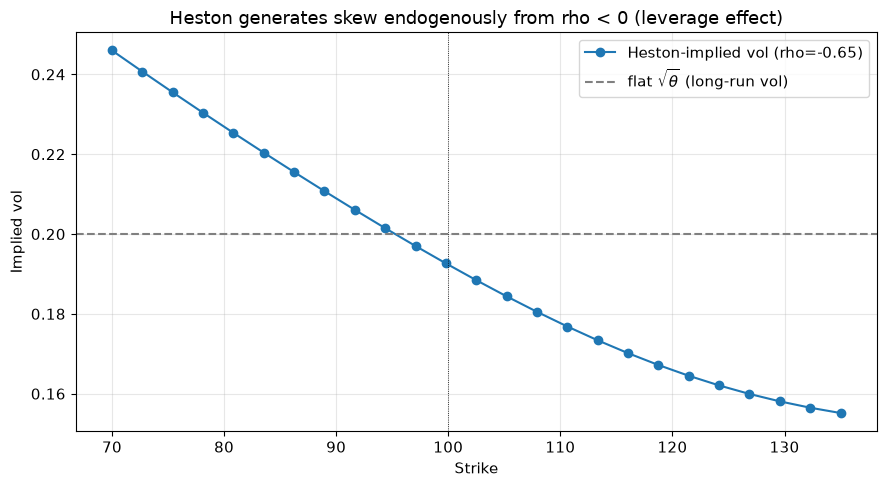

In [18]:
# The Heston smile: strike-dependent implied vol, generated purely from the SDE parameters above
strikes = np.linspace(70, 135, 25)
heston_ivs = []
for K_ in strikes:
    price_K = heston_call_price(S0, K_, T0, r, q, kappa_h, theta_h, xi_h, rho_h, v0_h)
    heston_ivs.append(implied_vol_brent(price_K, S0, K_, T0, r, q, "call"))

fig, ax = plt.subplots()
ax.plot(strikes, heston_ivs, "o-", label=f"Heston-implied vol (rho={rho_h})")
ax.axhline(np.sqrt(theta_h), color="gray", ls="--", label=r"flat $\sqrt{\theta}$ (long-run vol)")
ax.axvline(S0, color="k", lw=0.6, ls=":")
ax.set_xlabel("Strike"); ax.set_ylabel("Implied vol"); ax.legend()
ax.set_title("Heston generates skew endogenously from rho < 0 (leverage effect)")
plt.tight_layout(); plt.show()

## 9. Local volatility — Dupire's formula

**Source:** Dupire (1994), *Pricing with a Smile*, Risk Magazine. Rather than adding a
stochastic factor, **local volatility** asks: is there a *deterministic* function
$\sigma_{\text{loc}}(S,t)$ under which GBM-with-varying-vol reprices every European option in
the observed market exactly? Dupire showed the answer is yes (given a full, arbitrage-free
surface of call prices $C(K,T)$), with a closed-form formula recovering it from the
strike/maturity partial derivatives of that price surface:

$$
\sigma_{\text{loc}}^2(K,T) = \frac{\dfrac{\partial C}{\partial T} + (r-q)K\dfrac{\partial C}{\partial K} + qC}{\tfrac12 K^2 \dfrac{\partial^2 C}{\partial K^2}}
$$

We treat the Heston model above as a stand-in "true market": compute its call price surface
on a $(K,T)$ grid, then apply Dupire's formula via finite differences on that surface to
recover the local vol surface. Local vol is a *calibration device*, not a claim about how
volatility really moves — it reprices the vanilla smile perfectly by construction, but implies
unrealistic forward-smile dynamics (the smile flattens too fast going forward in time), which
is precisely the dynamics problem stochastic-vol models like Heston/SABR are built to fix.

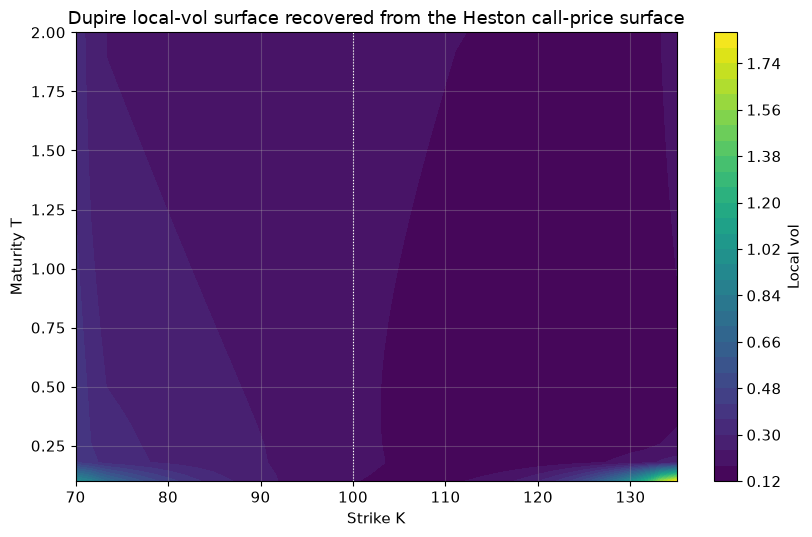

Local vol at K=100, T=1.0 (nearest grid point): 0.1915
Compare Heston instantaneous vol sqrt(v0):            0.2000


In [19]:
def call_price_surface(K_grid, T_grid):
    C = np.empty((len(T_grid), len(K_grid)))
    for i, T_ in enumerate(T_grid):
        for j, K_ in enumerate(K_grid):
            C[i, j] = heston_call_price(S0, K_, T_, r, q, kappa_h, theta_h, xi_h, rho_h, v0_h)
    return C

K_grid = np.linspace(70, 135, 40)
T_grid = np.linspace(0.1, 2.0, 25)
C_surf = call_price_surface(K_grid, T_grid)

dK = K_grid[1] - K_grid[0]
dT = T_grid[1] - T_grid[0]

dC_dT = np.gradient(C_surf, dT, axis=0)
dC_dK = np.gradient(C_surf, dK, axis=1)
d2C_dK2 = np.gradient(dC_dK, dK, axis=1)

KK, TT = np.meshgrid(K_grid, T_grid)
numerator = dC_dT + (r - q) * KK * dC_dK + q * C_surf
denominator = 0.5 * KK**2 * d2C_dK2
denominator = np.where(denominator < 1e-8, np.nan, denominator)   # guard against numerical noise
local_var = numerator / denominator
local_vol = np.sqrt(np.clip(local_var, 1e-6, 4.0))

fig, ax = plt.subplots(figsize=(8.5, 5.5))
cf = ax.contourf(KK, TT, local_vol, levels=30, cmap="viridis")
plt.colorbar(cf, ax=ax, label="Local vol")
ax.set_xlabel("Strike K"); ax.set_ylabel("Maturity T")
ax.set_title("Dupire local-vol surface recovered from the Heston call-price surface")
ax.axvline(S0, color="w", lw=0.8, ls=":")
plt.tight_layout(); plt.show()

print(f"Local vol at K={S0:.0f}, T=1.0 (nearest grid point): {local_vol[np.argmin(abs(T_grid-1)), np.argmin(abs(K_grid-S0))]:.4f}")
print(f"Compare Heston instantaneous vol sqrt(v0):            {np.sqrt(v0_h):.4f}")

## 10. The SABR model

**Source:** Hagan, Kumar, Lesniewski & Woodward (2002), *Managing Smile Risk*, Wilmott
Magazine. SABR ("stochastic alpha-beta-rho") models the forward price and its volatility as a
correlated pair:

$$
dF_t = \alpha_t F_t^\beta\,dW_t^F, \qquad d\alpha_t = \nu \alpha_t\,dW_t^\alpha, \qquad d\langle W^F, W^\alpha\rangle_t = \rho\,dt
$$

It is widely used on interest-rate desks specifically because it doesn't require a numerical
PDE or Fourier inversion to price: Hagan et al. derived a highly accurate **asymptotic
closed-form implied-vol formula** directly, by singular perturbation expansion. For
$F \ne K$ (using $\beta=1$, i.e. lognormal, to keep the formula compact):

$$
\sigma_{\text{imp}}(K) \approx \frac{\alpha}{F K}\cdot\frac{z}{x(z)}\left[1 + \left(\frac{\rho\nu\alpha}{4} + \frac{2-3\rho^2}{24}\nu^2\right)T\right] \Big|_{\beta=1\text{ simplification}}
$$

with $z = \frac{\nu}{\alpha}\ln(F/K)$ and $x(z) = \ln\!\left(\frac{\sqrt{1-2\rho z + z^2} + z - \rho}{1-\rho}\right)$.
We calibrate $(\alpha, \rho, \nu)$ by least squares directly to the Heston smile computed
above — a common desk workflow: fit SABR to whatever generated the market smile (an exotic
stochastic-vol model, or actual market quotes) because SABR's parameters have direct trading
intuition ($\rho$ = skew, $\nu$ = smile curvature/convexity) and its formula reprices in
microseconds, which matters for interactive risk systems.

Calibrated SABR (beta=0.9 fixed): alpha=0.3072  rho=-0.7079  nu=0.4024
Fit RMSE vs Heston smile: 0.00058 vol points


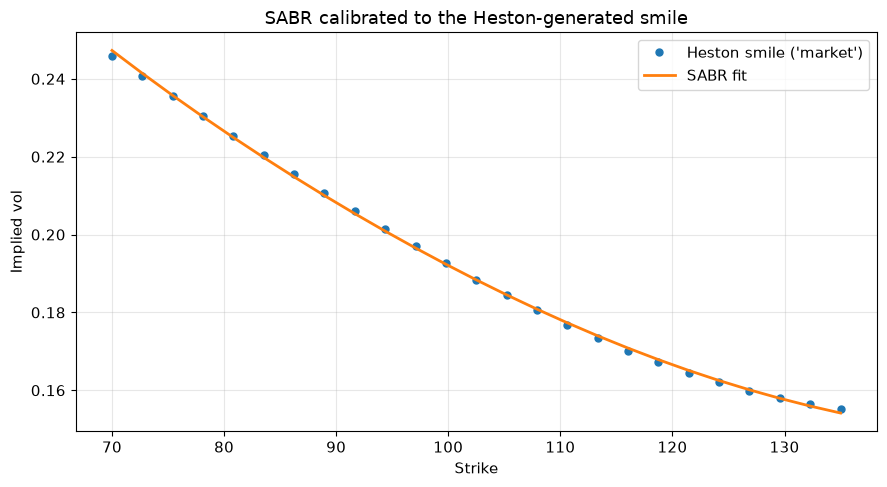

In [20]:
def sabr_implied_vol(F, K, T, alpha, beta, rho, nu):
    F, K = np.asarray(F, dtype=float), np.asarray(K, dtype=float)
    K = np.where(np.isclose(F, K), K + 1e-8, K)   # ATM strike needs a nudge (formula has removable 0/0)
    logFK = np.log(F / K)
    FK_beta = (F * K) ** ((1 - beta) / 2)
    z = (nu / alpha) * FK_beta * logFK
    x_z = np.log((np.sqrt(1 - 2 * rho * z + z**2) + z - rho) / (1 - rho))
    z_over_x = np.where(np.abs(z) < 1e-12, 1.0, z / x_z)

    A = alpha / (FK_beta * (1 + (1 - beta)**2 / 24 * logFK**2 + (1 - beta)**4 / 1920 * logFK**4))
    B = 1 + T * ((1 - beta)**2 / 24 * alpha**2 / FK_beta**2
                 + 0.25 * rho * beta * nu * alpha / FK_beta
                 + (2 - 3 * rho**2) / 24 * nu**2)
    return A * z_over_x * B

def calibrate_sabr(strikes, market_ivs, F, T, beta=0.9):
    def resid(params):
        alpha, rho, nu = params
        model = sabr_implied_vol(F, strikes, T, alpha, beta, rho, nu)
        return model - market_ivs

    x0 = [0.2, -0.3, 0.5]
    bounds = ([1e-4, -0.999, 1e-4], [3.0, 0.999, 5.0])
    result = least_squares(resid, x0, bounds=bounds)
    return result.x   # alpha, rho, nu

alpha_fit, rho_fit, nu_fit = calibrate_sabr(strikes, np.array(heston_ivs), S0, T0)
sabr_fit_ivs = sabr_implied_vol(S0, strikes, T0, alpha_fit, 0.9, rho_fit, nu_fit)

print(f"Calibrated SABR (beta=0.9 fixed): alpha={alpha_fit:.4f}  rho={rho_fit:.4f}  nu={nu_fit:.4f}")
rmse = np.sqrt(np.mean((sabr_fit_ivs - np.array(heston_ivs))**2))
print(f"Fit RMSE vs Heston smile: {rmse:.5f} vol points")

fig, ax = plt.subplots()
ax.plot(strikes, heston_ivs, "o", label="Heston smile ('market')", ms=5)
ax.plot(strikes, sabr_fit_ivs, "-", label="SABR fit", lw=2)
ax.set_xlabel("Strike"); ax.set_ylabel("Implied vol"); ax.legend()
ax.set_title("SABR calibrated to the Heston-generated smile")
plt.tight_layout(); plt.show()

## 11. Jump-diffusion — Merton (1976)

**Source:** Merton (1976), *Option Pricing When Underlying Stock Returns Are Discontinuous*,
J. Fin. Econ. Stochastic volatility isn't the only way to break Black-Scholes' flat smile.
Merton adds a compound Poisson jump process to GBM:

$$
\frac{dS_t}{S_{t^-}} = (r - q - \lambda\kappa)\,dt + \sigma\,dW_t + dJ_t, \qquad J_t = \sum_{i=1}^{N_t}(Y_i - 1)
$$

where $N_t$ is Poisson with intensity $\lambda$ (jumps per year) and $\ln Y_i \sim
\mathcal N(\mu_J, \delta_J^2)$, so $\kappa = \mathbb E[Y-1] = e^{\mu_J + \delta_J^2/2} - 1$ is
subtracted from the drift to keep $S_t$ a risk-neutral martingale (compensated jumps). Because
jump sizes are independent of the Brownian part and Poisson-distributed, the price is a simple
**closed-form Poisson mixture of Black-Scholes prices**, conditioning on the number of jumps
$n$ that occur before expiry:

$$
C_{\text{Merton}} = \sum_{n=0}^{\infty} \frac{e^{-\lambda' T}(\lambda' T)^n}{n!}\, C_{\text{BS}}\!\left(S, K, T, r_n, q, \sigma_n\right), \qquad
\lambda' = \lambda(1+\kappa),\ \ \sigma_n^2 = \sigma^2 + \frac{n\delta_J^2}{T},\ \ r_n = r - \lambda\kappa + \frac{n(\mu_J + \delta_J^2/2)}{T}
$$

Truncating the (rapidly-converging, thanks to $n!$) sum at $n_{\max}\approx 40$ is more than
enough for double precision. Unlike Heston's *stochastic* vol, jump risk generates smile/skew
even with **constant diffusion vol** $\sigma$ — because a rare, large downside jump has an
outsized effect on OTM put prices relative to what constant-vol diffusion would imply, and
that difference is exactly what the implied-vol inversion is picking up.

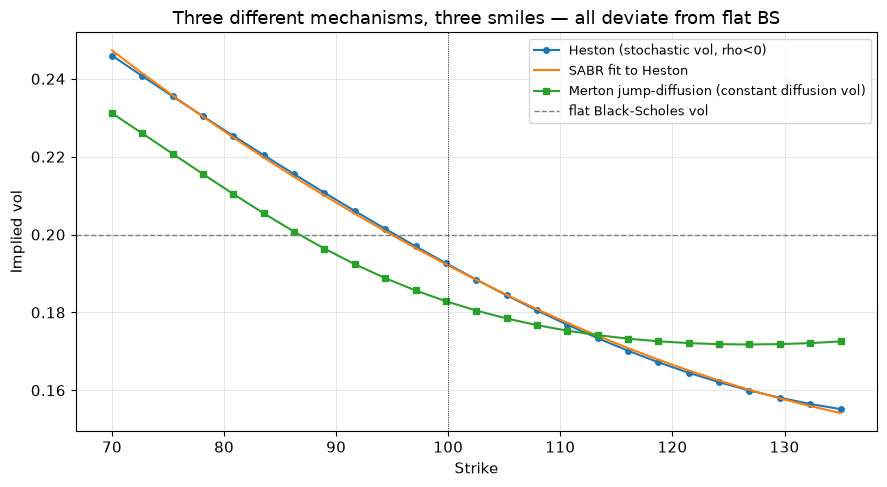

In [21]:
import math

def merton_jump_price(S, K, T, r, q, sigma, lam, mu_J, delta_J, kind="call", n_max=40):
    kappa_j = np.exp(mu_J + 0.5 * delta_J**2) - 1
    lam_prime = lam * (1 + kappa_j)
    total = 0.0
    for n in range(n_max):
        poisson_w = np.exp(-lam_prime * T) * (lam_prime * T) ** n / math.factorial(n)
        sigma_n = np.sqrt(sigma**2 + n * delta_J**2 / T)
        r_n = r - lam * kappa_j + n * (mu_J + 0.5 * delta_J**2) / T
        total += poisson_w * bs_price(S, K, T, r_n, q, sigma_n, kind)
    return total

# Parameters: rare, negative, moderately-sized jumps -- the classic "crash risk" calibration
lam_j, mu_j, delta_j, sigma_diff = 0.4, -0.12, 0.18, 0.14

merton_ivs = []
for K_ in strikes:
    price_K = merton_jump_price(S0, K_, T0, r, q, sigma_diff, lam_j, mu_j, delta_j, "call")
    merton_ivs.append(implied_vol_brent(price_K, S0, K_, T0, r, q, "call"))

fig, ax = plt.subplots()
ax.plot(strikes, heston_ivs, "o-", label="Heston (stochastic vol, rho<0)", ms=4)
ax.plot(strikes, sabr_fit_ivs, "-", label="SABR fit to Heston", lw=1.5)
ax.plot(strikes, merton_ivs, "s-", label="Merton jump-diffusion (constant diffusion vol)", ms=4)
ax.axhline(sigma0, color="gray", ls="--", lw=1, label="flat Black-Scholes vol")
ax.axvline(S0, color="k", lw=0.6, ls=":")
ax.set_xlabel("Strike"); ax.set_ylabel("Implied vol"); ax.legend(fontsize=9)
ax.set_title("Three different mechanisms, three smiles — all deviate from flat BS")
plt.tight_layout(); plt.show()

## 12. Building and checking a volatility surface

A production vol surface must be **arbitrage-free** in two senses:

- **Calendar-spread arbitrage:** total variance $w(K,T) = \sigma_{\text{imp}}^2(K,T)\cdot T$
  must be non-decreasing in $T$ at fixed strike (otherwise a calendar spread is a static
  arbitrage — you could lock in a riskless profit by selling the shorter-dated option and
  buying the longer-dated one).
- **Butterfly (strike) arbitrage:** the implied risk-neutral density, $\propto \partial^2
  C/\partial K^2$, must be non-negative everywhere — a violation means the market-implied
  probability of some outcome is negative, which is nonsensical and exploitable with a
  butterfly spread.

We build a small multi-maturity surface from the Heston model (which is arbitrage-free by
construction, since it comes from one consistent SDE) and confirm both conditions hold
numerically — then show what a naive, badly-interpolated surface (e.g. linear interpolation in
implied vol across strikes) can do to the butterfly condition, which is why practitioners
interpolate in *total variance* / use parametric smile models like SVI or SABR instead of
interpolating implied vol directly.

Calendar-spread condition (total variance non-decreasing in T): OK
Butterfly condition (implied density >= 0) at T=1: OK


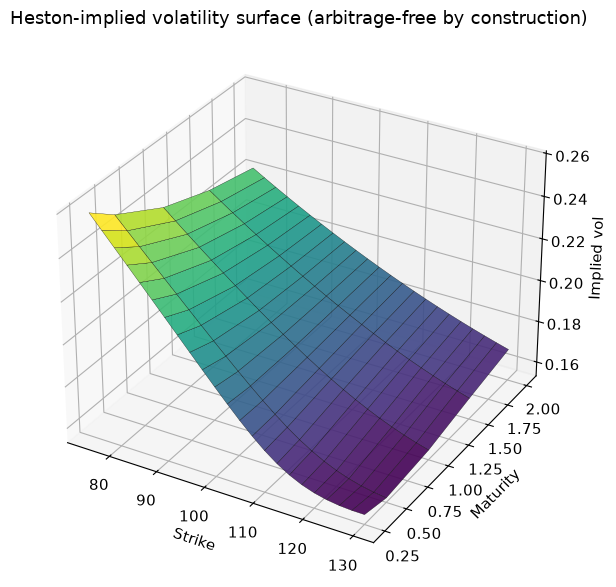

In [22]:
T_surf = [0.25, 0.5, 1.0, 1.5, 2.0]
K_surf = np.linspace(75, 130, 23)

iv_surface = np.zeros((len(T_surf), len(K_surf)))
for i, T_ in enumerate(T_surf):
    for j, K_ in enumerate(K_surf):
        price_K = heston_call_price(S0, K_, T_, r, q, kappa_h, theta_h, xi_h, rho_h, v0_h)
        iv_surface[i, j] = implied_vol_brent(price_K, S0, K_, T_, r, q, "call")

total_var = iv_surface**2 * np.array(T_surf)[:, None]
calendar_ok = np.all(np.diff(total_var, axis=0) >= -1e-8)
print(f"Calendar-spread condition (total variance non-decreasing in T): {'OK' if calendar_ok else 'VIOLATED'}")

# Butterfly condition via discrete second derivative of price in K (should be >= 0, it's ~ density)
call_prices_row = np.array([heston_call_price(S0, K_, 1.0, r, q, kappa_h, theta_h, xi_h, rho_h, v0_h) for K_ in K_surf])
d2C = np.diff(call_prices_row, 2) / (K_surf[1] - K_surf[0])**2
butterfly_ok = np.all(d2C >= -1e-6)
print(f"Butterfly condition (implied density >= 0) at T=1: {'OK' if butterfly_ok else 'VIOLATED'}")

fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(projection="3d")
KK_s, TT_s = np.meshgrid(K_surf, T_surf)
ax.plot_surface(KK_s, TT_s, iv_surface, cmap="viridis", edgecolor="k", linewidth=0.2, alpha=0.9)
ax.set_xlabel("Strike"); ax.set_ylabel("Maturity"); ax.set_zlabel("Implied vol")
ax.set_title("Heston-implied volatility surface (arbitrage-free by construction)")
plt.tight_layout(); plt.show()

## 13. Trading structures and portfolio Greeks

A "position" is just a signed collection of options plus stock; its Greeks are the linear
combination of the Greeks of its legs (Greeks are additive because pricing is linear in the
number of contracts, even though price itself is nonlinear in spot). Some standard structures:

| Structure | Legs | View expressed |
|---|---|---|
| Long straddle | Long call + long put, same $K$ | Big move, either direction (long vol/gamma) |
| Bull call spread | Long call $K_1$ + short call $K_2 > K_1$ | Moderately bullish, capped, cheaper than outright call |
| Iron condor | Short OTM put spread + short OTM call spread | Range-bound, short vol |
| Covered call | Long stock + short OTM call | Yield enhancement, caps upside |
| Protective put | Long stock + long put | Insurance against downside |
| Calendar spread | Short near-dated + long far-dated, same $K$ | Long vega, short theta decay differential |

We compute payoff diagrams and, more importantly, the *net Greeks* of a small multi-leg book —
this is what actually gets risk-managed on a desk, not any individual option.

In [23]:
@dataclass
class Leg:
    kind: str      # "call", "put", "stock"
    qty: float     # + long, - short
    K: float = None

def price_leg(leg, S, T, r, q, sigma):
    if leg.kind == "stock":
        return leg.qty * S
    return leg.qty * bs_price(S, leg.K, T, r, q, sigma, leg.kind)

def greeks_leg(leg, S, T, r, q, sigma):
    if leg.kind == "stock":
        return {"delta": leg.qty, "gamma": 0.0, "vega": 0.0, "theta": 0.0, "rho": 0.0}
    g = bs_greeks(S, leg.K, T, r, q, sigma, leg.kind)
    return {k: leg.qty * v for k, v in g.items()}

def book_greeks(legs, S, T, r, q, sigma):
    total = {"delta": 0.0, "gamma": 0.0, "vega": 0.0, "theta": 0.0, "rho": 0.0}
    for leg in legs:
        g = greeks_leg(leg, S, T, r, q, sigma)
        for k in total:
            total[k] += g[k]
    return total

# Example book: an iron condor, short 100 units net, plus a delta hedge
iron_condor = [
    Leg("put", -1, K=90), Leg("put", +1, K=85),      # short put spread
    Leg("call", -1, K=110), Leg("call", +1, K=115),  # short call spread
]
net = book_greeks(iron_condor, S0, T0, r, q, sigma0)
print("Iron condor net Greeks (1 unit each leg):", {k: round(v, 4) for k, v in net.items()})

hedge_shares = -net["delta"]
hedged_book = iron_condor + [Leg("stock", hedge_shares)]
net_hedged = book_greeks(hedged_book, S0, T0, r, q, sigma0)
print(f"Delta hedge: {hedge_shares:.3f} shares  ->  net delta after hedge: {net_hedged['delta']:.6f}")

Iron condor net Greeks (1 unit each leg): {'delta': np.float64(-0.004), 'gamma': np.float64(-0.0049), 'vega': np.float64(-9.813), 'theta': np.float64(0.912), 'rho': np.float64(2.1756)}
Delta hedge: 0.004 shares  ->  net delta after hedge: 0.000000


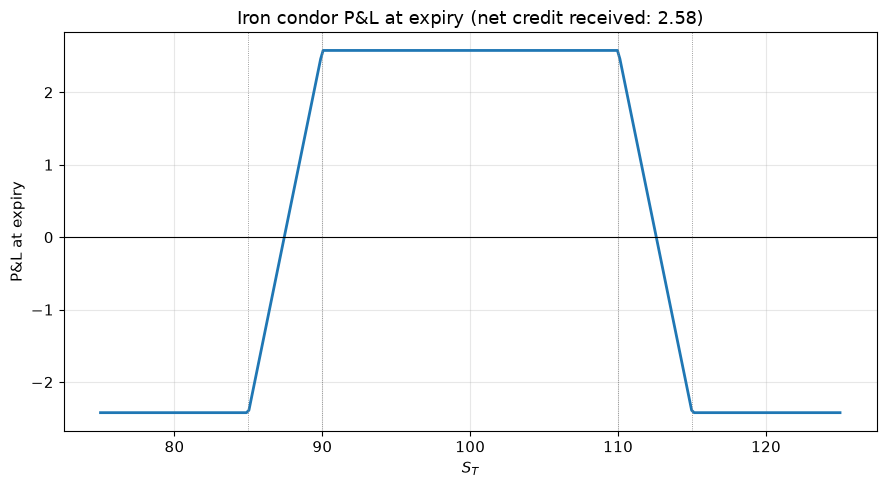

In [24]:
S_grid3 = np.linspace(75, 125, 300)
condor_payoff = sum(leg.qty * payoff(S_grid3, leg.K, leg.kind) for leg in iron_condor if leg.kind != "stock")
condor_premium_received = -sum(price_leg(leg, S0, T0, r, q, sigma0) for leg in iron_condor)
condor_pnl = condor_payoff + condor_premium_received

fig, ax = plt.subplots()
ax.plot(S_grid3, condor_pnl, lw=2)
ax.axhline(0, color="k", lw=0.8)
for leg in iron_condor:
    ax.axvline(leg.K, color="gray", lw=0.6, ls=":")
ax.set_xlabel("$S_T$"); ax.set_ylabel("P&L at expiry")
ax.set_title(f"Iron condor P&L at expiry (net credit received: {condor_premium_received:.2f})")
plt.tight_layout(); plt.show()

## 14. Delta-hedging simulation: theta vs. gamma P&L

A market maker who sells an option and delta-hedges discretely (not continuously) is exposed
to **hedging error**, whose distribution is closely tied to the Greeks. To second order in a
small time step $\Delta t$ and price move $\Delta S$, the P&L of a delta-hedged short option
position over one rebalancing interval is approximately:

$$
\text{P\&L} \approx -\left(\Theta\,\Delta t + \tfrac12 \Gamma\,(\Delta S)^2\right)
$$

For a short option, $\Theta > 0$ (time decay works for you) while $-\tfrac12\Gamma(\Delta S)^2$
is a cost that grows with realized variance — **you are short gamma, so realized moves hurt
you, but you collect theta as compensation.** If realized vol equals the vol you sold at
(implied vol), these roughly offset in expectation; if realized vol undershoots, theta wins;
if it overshoots, gamma losses dominate. We simulate this directly: sell an ATM call, delta
hedge at a fixed frequency along simulated GBM paths, and look at the P&L distribution as a
function of rehedging frequency and of the realized-vs-implied vol gap.

Sold implied vol: 0.2
Realized = implied (0.2):  mean P&L = -0.5971  std = 1.0251
Realized < implied (0.12):      mean P&L = 2.5914  std = 1.1182
Realized > implied (0.30):      mean P&L = -4.5803  std = 2.3352


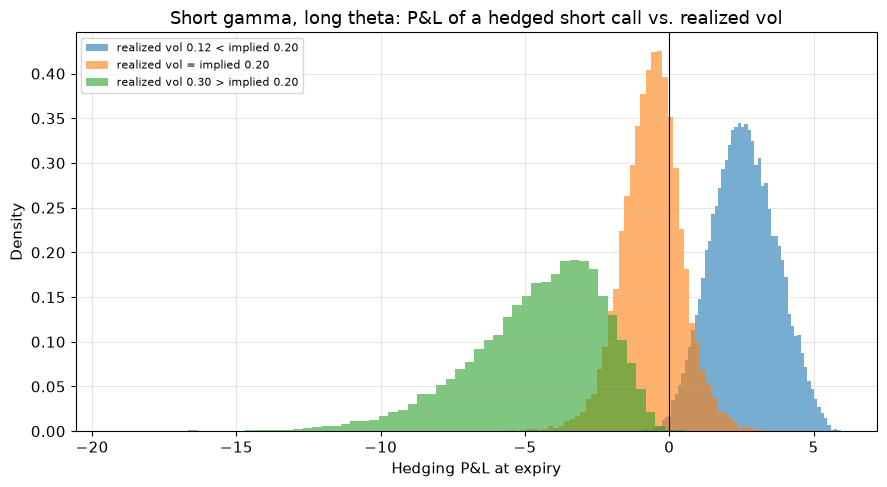

In [25]:
def delta_hedge_pnl(S0_, K, T, r, q, sigma_sold, sigma_realized, n_paths, n_steps, seed=0):
    rng = np.random.default_rng(seed)
    dt = T / n_steps
    Z = rng.standard_normal((n_paths, n_steps))

    S_path = np.full(n_paths, S0_)
    cash = bs_price(S0_, K, T, r, q, sigma_sold, "call")     # premium received from selling the call
    delta_prev = bs_greeks(S0_, K, T, r, q, sigma_sold, "call")["delta"]
    cash -= delta_prev * S0_                                   # buy delta shares to hedge

    for step in range(n_steps):
        t_remaining = T - step * dt
        S_path = S_path * np.exp((r - q - 0.5 * sigma_realized**2) * dt + sigma_realized * np.sqrt(dt) * Z[:, step])
        cash *= np.exp(r * dt)                                  # cash account accrues at r

        if step < n_steps - 1:
            tau = T - (step + 1) * dt
            delta_new = bs_greeks(S_path, K, tau, r, q, sigma_sold, "call")["delta"]
        else:
            delta_new = (S_path > K).astype(float)               # delta jumps to 0/1 at expiry
        cash -= (delta_new - delta_prev) * S_path                # rebalance
        delta_prev = delta_new

    option_payoff = payoff(S_path, K, "call")
    final_stock_value = delta_prev * S_path
    pnl = cash + final_stock_value - option_payoff
    return pnl

pnl_matched = delta_hedge_pnl(S0, K0, T0, r, q, sigma0, sigma0, n_paths=20_000, n_steps=50)
pnl_realized_low = delta_hedge_pnl(S0, K0, T0, r, q, sigma0, 0.12, n_paths=20_000, n_steps=50)
pnl_realized_high = delta_hedge_pnl(S0, K0, T0, r, q, sigma0, 0.30, n_paths=20_000, n_steps=50)

print(f"Sold implied vol: {sigma0}")
print(f"Realized = implied ({sigma0}):  mean P&L = {pnl_matched.mean():.4f}  std = {pnl_matched.std():.4f}")
print(f"Realized < implied (0.12):      mean P&L = {pnl_realized_low.mean():.4f}  std = {pnl_realized_low.std():.4f}")
print(f"Realized > implied (0.30):      mean P&L = {pnl_realized_high.mean():.4f}  std = {pnl_realized_high.std():.4f}")

fig, ax = plt.subplots()
ax.hist(pnl_realized_low, bins=60, alpha=0.6, label="realized vol 0.12 < implied 0.20", density=True)
ax.hist(pnl_matched, bins=60, alpha=0.6, label="realized vol = implied 0.20", density=True)
ax.hist(pnl_realized_high, bins=60, alpha=0.6, label="realized vol 0.30 > implied 0.20", density=True)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Hedging P&L at expiry"); ax.set_ylabel("Density"); ax.legend(fontsize=8)
ax.set_title("Short gamma, long theta: P&L of a hedged short call vs. realized vol")
plt.tight_layout(); plt.show()

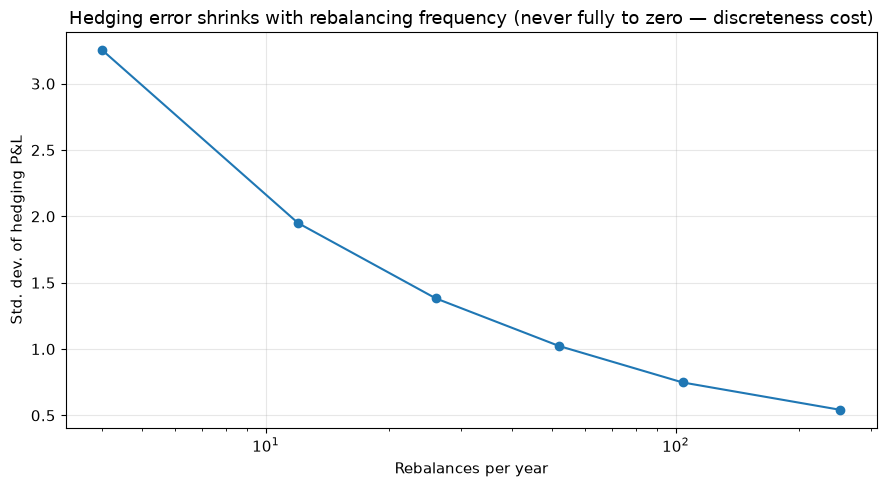

In [26]:
# Rehedging frequency: hedging error should shrink as we rebalance more often
freqs = [4, 12, 26, 52, 104, 252]
stds = []
for n_steps in freqs:
    pnl = delta_hedge_pnl(S0, K0, T0, r, q, sigma0, sigma0, n_paths=8_000, n_steps=n_steps, seed=3)
    stds.append(pnl.std())

fig, ax = plt.subplots()
ax.plot(freqs, stds, "o-")
ax.set_xscale("log")
ax.set_xlabel("Rebalances per year"); ax.set_ylabel("Std. dev. of hedging P&L")
ax.set_title("Hedging error shrinks with rebalancing frequency (never fully to zero — discreteness cost)")
plt.tight_layout(); plt.show()

## 15. Model comparison — what to use when

In [27]:
comparison = pd.DataFrame([
    ["Black-Scholes-Merton", "Closed form", "Instant", "Baseline quoting, back-of-envelope Greeks", "No smile; constant vol"],
    ["Binomial / trinomial tree", "O(N^2)", "Fast (ms)", "American equity options, simple payoffs", "Slow convergence vs. FD/analytic for vanillas"],
    ["Monte Carlo (+ variance reduction)", "O(1/sqrt(n))", "Moderate-slow", "Path-dependent / high-dim payoffs (Asian, basket)", "Native European only; American needs LSM"],
    ["Longstaff-Schwartz (LSM)", "O(n_paths * n_steps)", "Slow", "American / Bermudan options, high dimension", "Regression bias; basis-function choice matters"],
    ["Finite difference (Crank-Nicolson)", "O(M*N)", "Fast", "American options, low dimension (1-2 factors)", "Curse of dimensionality beyond ~2-3 factors"],
    ["Heston (stochastic vol)", "Semi-analytic (Fourier)", "Fast (ms)", "Vanilla smile + realistic vol dynamics, vol derivatives", "5 params to calibrate; can misprice short-dated skew"],
    ["Dupire local vol", "Derived from full C(K,T) surface", "Depends on surface build", "Exotic pricing consistent with observed vanilla smile", "Poor forward-smile dynamics; needs clean full surface"],
    ["SABR", "Closed-form asymptotic", "Instant", "Rates desks; smile interpolation/extrapolation per-tenor", "Not a global dynamic model across tenors on its own"],
    ["Merton jump-diffusion", "Closed form (Poisson sum)", "Fast", "Short-dated skew/crash risk, event risk", "Jump params hard to estimate from historical data alone"],
], columns=["Model", "Pricing method", "Typical speed", "Best used for", "Main limitation"])

pd.set_option("display.max_colwidth", 60)
comparison

,Model,Pricing method,Typical speed,Best used for,Main limitation
0,Black-Scholes-Merton,Closed form,Instant,"Baseline quoting, back-of-envelope Greeks",No smile; constant vol
1,Binomial / trinomial tree,O(N^2),Fast (ms),"American equity options, simple payoffs",Slow convergence vs. FD/analytic for vanillas
2,Monte Carlo (+ variance reduction),O(1/sqrt(n)),Moderate-slow,"Path-dependent / high-dim payoffs (Asian, basket)",Native European only; American needs LSM
3,Longstaff-Schwartz (LSM),O(n_paths * n_steps),Slow,"American / Bermudan options, high dimension",Regression bias; basis-function choice matters
4,Finite difference (Crank-Nicolson),O(M*N),Fast,"American options, low dimension (1-2 factors)",Curse of dimensionality beyond ~2-3 factors
5,Heston (stochastic vol),Semi-analytic (Fourier),Fast (ms),"Vanilla smile + realistic vol dynamics, vol derivatives",5 params to calibrate; can misprice short-dated skew
6,Dupire local vol,"Derived from full C(K,T) surface",Depends on surface build,Exotic pricing consistent with observed vanilla smile,Poor forward-smile dynamics; needs clean full surface
7,SABR,Closed-form asymptotic,Instant,Rates desks; smile interpolation/extrapolation per-tenor,Not a global dynamic model across tenors on its own
8,Merton jump-diffusion,Closed form (Poisson sum),Fast,"Short-dated skew/crash risk, event risk",Jump params hard to estimate from historical data alone


## 16. References

1. Black, F. & Scholes, M. (1973). *The Pricing of Options and Corporate Liabilities*. Journal of Political Economy, 81(3), 637-654.
2. Merton, R. C. (1973). *Theory of Rational Option Pricing*. Bell Journal of Economics and Management Science, 4(1), 141-183.
3. Merton, R. C. (1976). *Option Pricing When Underlying Stock Returns Are Discontinuous*. Journal of Financial Economics, 3(1-2), 125-144.
4. Cox, J. C., Ross, S. A. & Rubinstein, M. (1979). *Option Pricing: A Simplified Approach*. Journal of Financial Economics, 7(3), 229-263.
5. Brennan, M. J. & Schwartz, E. S. (1977). *The Valuation of American Put Options*. Journal of Finance, 32(2), 449-462.
6. Heston, S. L. (1993). *A Closed-Form Solution for Options with Stochastic Volatility with Applications to Bond and Currency Options*. Review of Financial Studies, 6(2), 327-343.
7. Albrecher, H., Mayer, P., Schoutens, W. & Tistaert, J. (2007). *The Little Heston Trap*. Wilmott Magazine, January 2007.
8. Dupire, B. (1994). *Pricing with a Smile*. Risk Magazine, 7(1), 18-20.
9. Hagan, P. S., Kumar, D., Lesniewski, A. S. & Woodward, D. E. (2002). *Managing Smile Risk*. Wilmott Magazine, September 2002.
10. Longstaff, F. A. & Schwartz, E. S. (2001). *Valuing American Options by Simulation: A Simple Least-Squares Approach*. Review of Financial Studies, 14(1), 113-147.
11. Gatheral, J. (2004). *A Parsimonious Arbitrage-Free Implied Volatility Parameterization with Application to the Valuation of Volatility Derivatives* (the SVI parameterization). Presentation, Global Derivatives.
12. Lord, R., Koekkoek, R. & van Dijk, D. (2010). *A Comparison of Biased Simulation Schemes for Stochastic Volatility Models*. Quantitative Finance, 10(2), 177-194.
13. Feller, W. (1951). *Two Singular Diffusion Problems*. Annals of Mathematics, 54(1), 173-182.
14. Gatheral, J. (2006). *The Volatility Surface: A Practitioner's Guide*. Wiley Finance.
15. Hull, J. C. (2022). *Options, Futures, and Other Derivatives* (11th ed.). Pearson.